In [123]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import linear_model

## Reading dataset

In [124]:
df = pd.read_csv('SOCR-HeightWeight.csv')
df.drop(columns=['Index'], inplace=True)
df.head()

,Height(Inches),Weight(Pounds)
0,65.78331,112.9925
1,71.51521,136.4873
2,69.39874,153.0269
3,68.21660,142.3354
4,67.78781,144.2971


## step 1

In [125]:
msk = np.random.randint(0 , 100 , len(df)) > 80
train = df[~msk]
test = df[msk]

## step 2

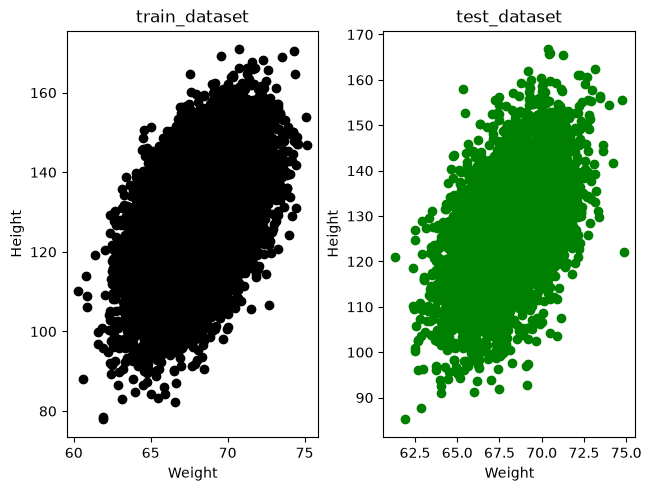

In [126]:
fig, axs = plt.subplots(ncols=2, layout='constrained')
axs[0].scatter(train['Height(Inches)'], train['Weight(Pounds)'], color='black');
axs[1].scatter(test['Height(Inches)'], test['Weight(Pounds)'], color='green');
axs[0].set_title('train_dataset');
axs[1].set_title('test_dataset');
axs[0].set_xlabel('Weight');
axs[0].set_ylabel('Height');
axs[1].set_xlabel('Weight');
axs[1].set_ylabel('Height');

## step 3

In [133]:
regr = linear_model.LinearRegression()
regr.fit(train[['Weight(Pounds)']], train['Height(Inches)'])
intercept = regr.intercept_
coef = regr.coef_

np.float64(57.499218831449774)

## step 4

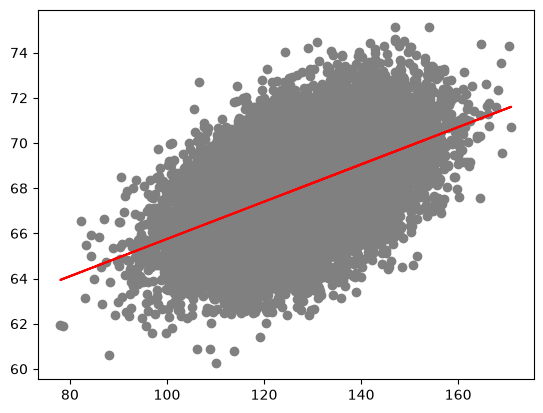

In [152]:
y_pred = regr.predict(train[['Weight(Pounds)']])

plt.scatter(train['Weight(Pounds)'], train['Height(Inches)'], color='gray');
plt.plot(train['Weight(Pounds)'], y_pred, color='red');

## step 5

In [169]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
y_pred_ = regr.predict(test[['Weight(Pounds)']])
mse = mean_squared_error(test['Weight(Pounds)'], y_pred_)
r2 = r2_score(test['Height(Inches)'], y_pred_)
print(f'mse : {mse}\nr2 : {r2 * 100}%')

mse : 3597.73225988703
r2 : 23.905018727891324%
